In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import tensorflow as tf
import numpy as np
import os

MODEL_PATH = "/content/drive/MyDrive/pratham/models/task10_efficientnetb0_baseline.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model Loaded")
print(model.input_shape)
print(model.output_shape)

Model Loaded
(None, 224, 224, 3)
(None, 1)


In [3]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,541,864 (17.33 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

 Optimizer params: 328,196 (1.25 MB)

In [4]:
BASE_DIR = "/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
TEST_DIR  = os.path.join(BASE_DIR, "test")

NORMAL_DIR = os.path.join(TEST_DIR, "NORMAL")
PNEUMONIA_DIR = os.path.join(TEST_DIR, "PNEUMONIA")

In [5]:
from tensorflow.keras.preprocessing import image

IMG_SIZE = (224,224)

def load_image(img_path):

    img = image.load_img(
        img_path,
        target_size=IMG_SIZE
    )

    arr = image.img_to_array(img)

    arr = np.expand_dims(arr, axis=0)

    return arr

In [6]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_gen = ImageDataGenerator().flow_from_directory(
    TEST_DIR,
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print(test_gen.class_indices)

Found 624 images belonging to 2 classes.
{'NORMAL': 0, 'PNEUMONIA': 1}


In [7]:
loss, acc = model.evaluate(
    test_gen,
    verbose=1
)

print("Test Accuracy:", acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 39s 976ms/step - accuracy: 0.8942 - loss: 0.2551
Test Accuracy: 0.8942307829856873


In [8]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

pred_probs = model.predict(test_gen)

preds = (pred_probs > 0.5).astype(int)

y_true = test_gen.classes

print(classification_report(
    y_true,
    preds
))

print(confusion_matrix(
    y_true,
    preds
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 30s 757ms/step
              precision    recall  f1-score   support

           0       0.93      0.77      0.85       234
           1       0.88      0.97      0.92       390

    accuracy                           0.89       624
   macro avg       0.90      0.87      0.88       624
weighted avg       0.90      0.89      0.89       624

[[181  53]
 [ 13 377]]


In [9]:
import pandas as pd

filepaths = test_gen.filepaths

results = []

for fp, true_label, prob in zip(
    filepaths,
    y_true,
    pred_probs.flatten()
):

    pred = int(prob > 0.5)

    results.append([
        fp,
        true_label,
        pred,
        prob
    ])

df = pd.DataFrame(
    results,
    columns=[
        "path",
        "true",
        "pred",
        "prob"
    ]
)

df.head()

,path,true,pred,prob
0,/content/drive/MyDrive/pratham/datasets/chest_...,0,0,0.101235
1,/content/drive/MyDrive/pratham/datasets/chest_...,0,0,0.014503
2,/content/drive/MyDrive/pratham/datasets/chest_...,0,0,0.217028
3,/content/drive/MyDrive/pratham/datasets/chest_...,0,0,0.101181
4,/content/drive/MyDrive/pratham/datasets/chest_...,0,0,0.130455


In [10]:
correct_normal = df[
    (df.true==0) &
    (df.pred==0)
].head(3)

correct_pneumonia = df[
    (df.true==1) &
    (df.pred==1)
].head(3)

misclassified_normal = df[
    (df.true==0) &
    (df.pred==1)
].head(3)

misclassified_pneumonia = df[
    (df.true==1) &
    (df.pred==0)
].head(3)

print(len(correct_normal))
print(len(correct_pneumonia))
print(len(misclassified_normal))
print(len(misclassified_pneumonia))

3
3
3
3


In [11]:
for layer in model.layers[-20:]:
    print(layer.name)

block7a_expand_bn
block7a_expand_activation
block7a_dwconv
block7a_bn
block7a_activation
block7a_se_squeeze
block7a_se_reshape
block7a_se_reduce
block7a_se_expand
block7a_se_excite
block7a_project_conv
block7a_project_bn
top_conv
top_bn
top_activation
global_average_pooling2d
dropout
dense
dropout_1
dense_1


In [12]:
LAST_CONV_LAYER = "top_conv"

In [13]:
import tensorflow as tf

def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name
):

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(
                last_conv_layer_name
            ).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array
        )

        loss = predictions[:,0]

    grads = tape.gradient(
        loss,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0,1,2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        pooled_grads * conv_outputs,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    heatmap /= (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()

In [14]:
import cv2
import matplotlib.pyplot as plt

In [15]:
def show_gradcam(img_path):

    img_array = load_image(img_path)

    prob = float(
        model.predict(
            img_array,
            verbose=0
        )[0][0]
    )

    heatmap = make_gradcam_heatmap(
        img_array,
        model,
        LAST_CONV_LAYER
    )

    original = cv2.imread(img_path)
    original = cv2.cvtColor(
        original,
        cv2.COLOR_BGR2RGB
    )

    heatmap = cv2.resize(
        heatmap,
        (
            original.shape[1],
            original.shape[0]
        )
    )

    heatmap = np.uint8(
        255 * heatmap
    )

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap,
        0.4,
        0
    )

    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(heatmap)
    plt.title("Heatmap")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(overlay)
    plt.title(
        f"Prob={prob:.3f}"
    )
    plt.axis("off")

    plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


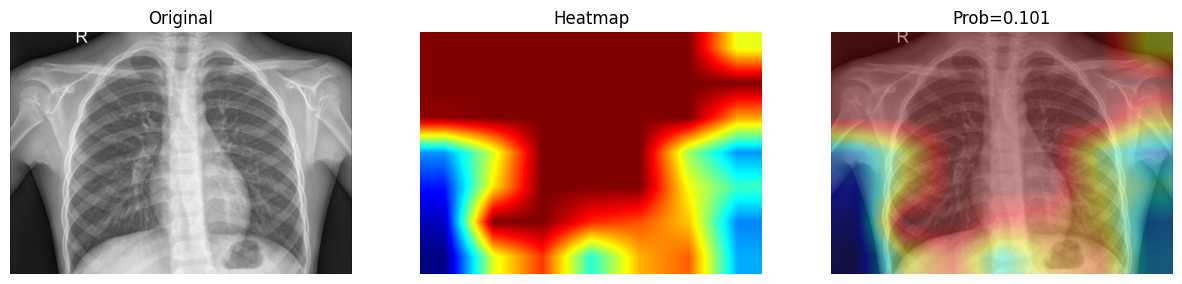

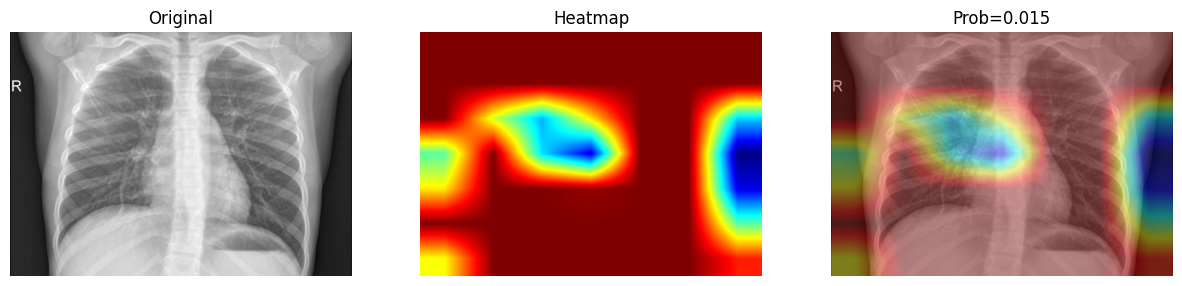

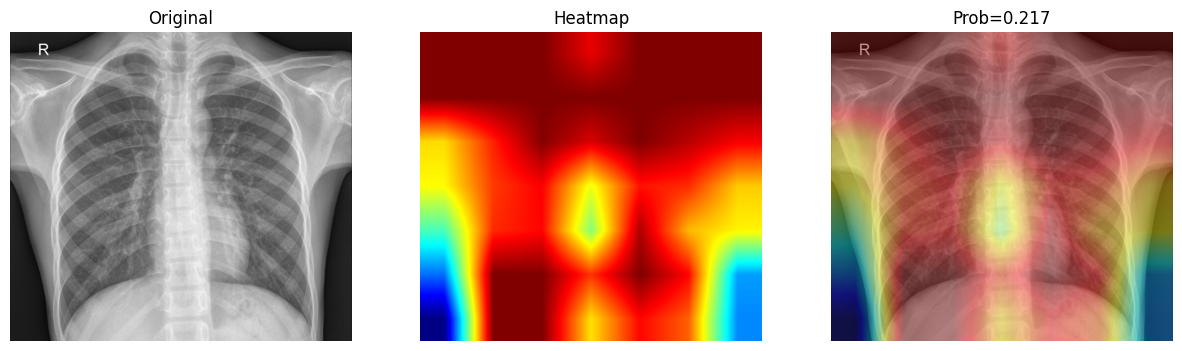

In [16]:
for p in correct_normal["path"]:
    show_gradcam(p)

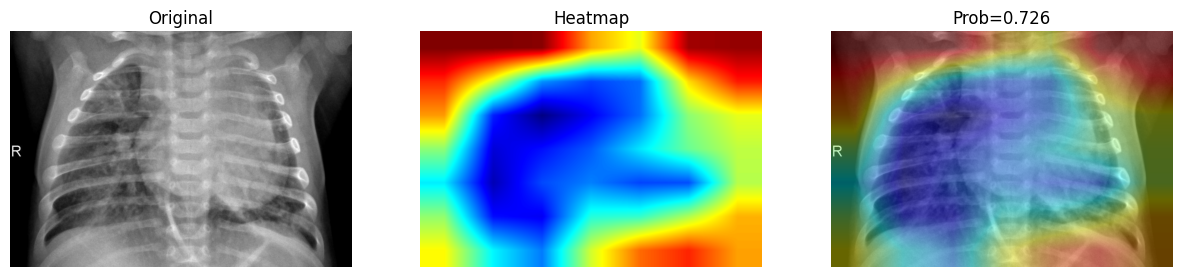

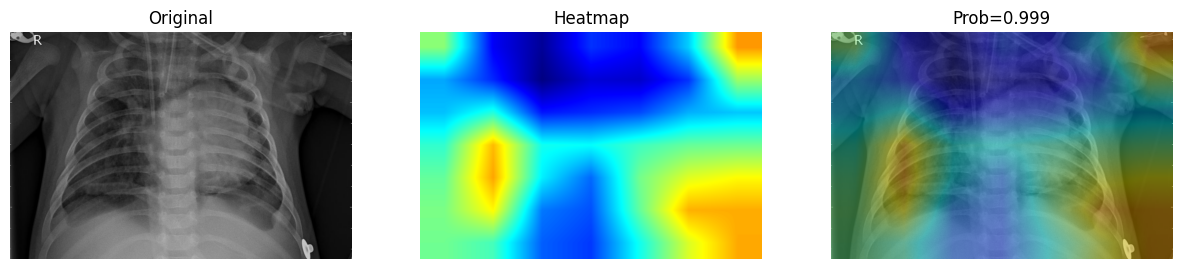

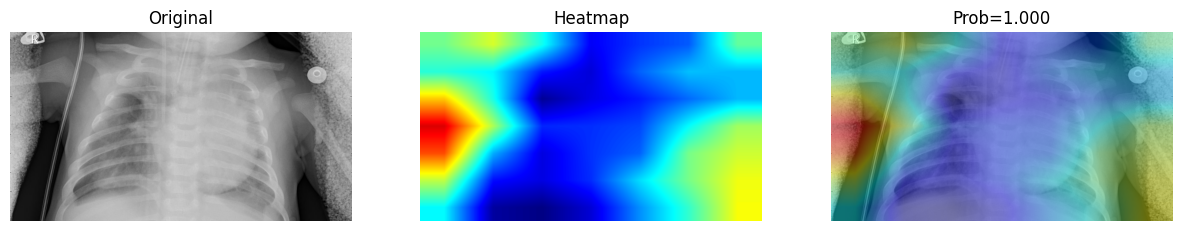

In [17]:
for p in correct_pneumonia["path"]:
    show_gradcam(p)

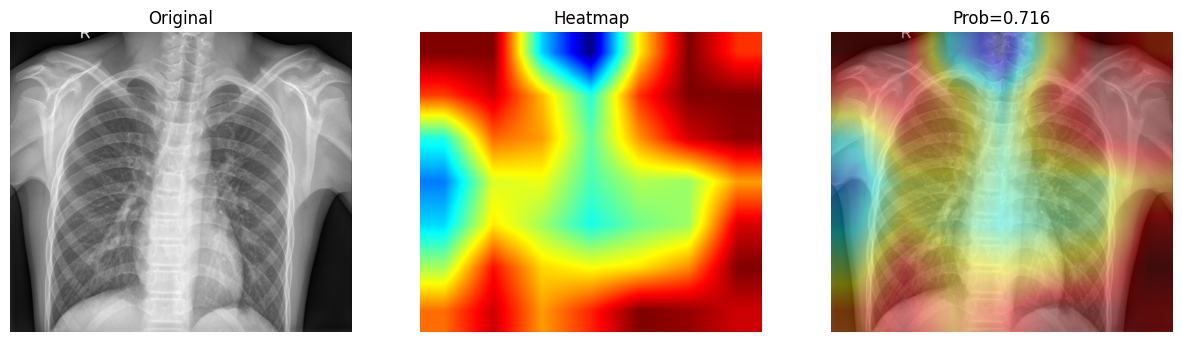

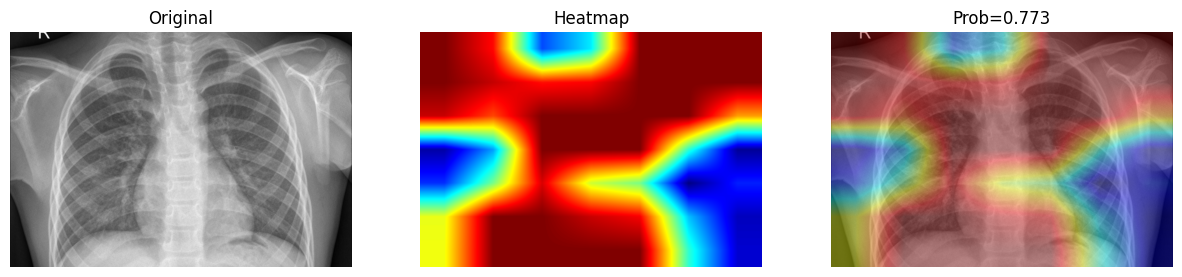

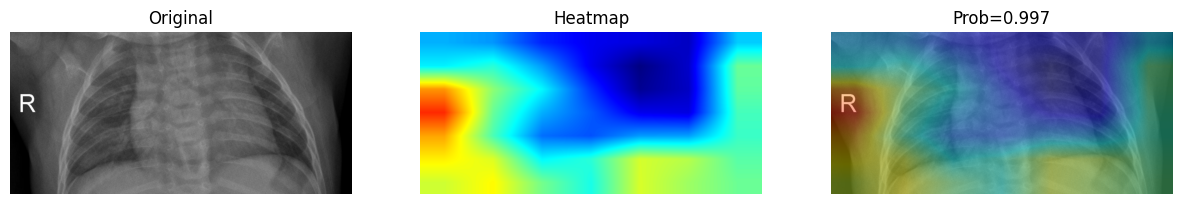

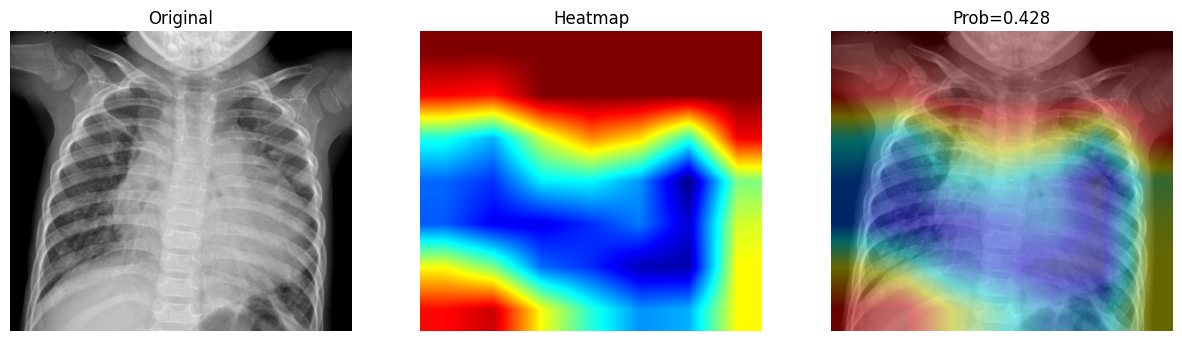

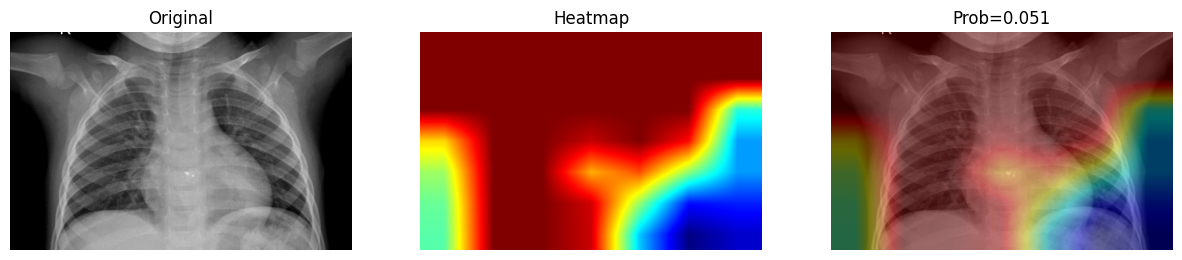

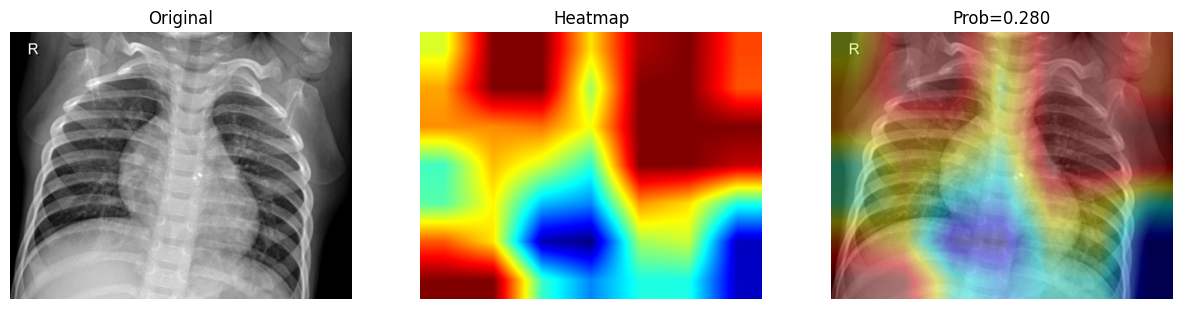

In [18]:
for p in misclassified_normal["path"]:
    show_gradcam(p)

for p in misclassified_pneumonia["path"]:
    show_gradcam(p)